In [30]:
# Built-in modules
import math

# Imports from Qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate
from qiskit.visualization import plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Imports from qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler


def grover_oracle(marked_states):
    """Build a Grover oracle for multiple marked states

    Here we assume all input marked states have the same number of bits

    Parameters:
        marked_states (str or list): Marked states of oracle

    Returns:
        QuantumCircuit: Quantum circuit representing Grover oracle
    """
    if not isinstance(marked_states, list):
        marked_states = [marked_states]
    # Compute the number of qubits in circuit
    num_qubits = len(marked_states[0])

    qc = QuantumCircuit(num_qubits)
    # Mark each target state in the input list
    for target in marked_states:
        # Flip target bit-string to match Qiskit bit-ordering
        rev_target = target[::-1]
        # Find the indices of all the '0' elements in bit-string
        zero_inds = [
            ind
            for ind in range(num_qubits)
            if rev_target.startswith("0", ind)
        ]
        # Add a multi-controlled Z-gate with pre- and post-applied X-gates (open-controls)
        # where the target bit-string has a '0' entry
        if zero_inds:
            qc.x(zero_inds)
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), inplace=True)
        if zero_inds:
            qc.x(zero_inds)
    return qc

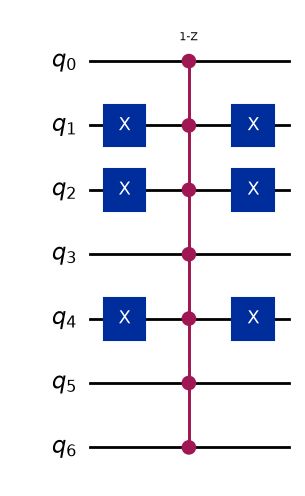

In [31]:
marked_states = ["1101001"]

oracle = grover_oracle(marked_states)

grover_op = grover_operator(oracle)

oracle.draw(output="mpl", style="iqp")

In [32]:
# Theoretical optimal number of Grover iterations
N = 2 ** grover_op.num_qubits
M = len(marked_states)

optimal_num_iterations = math.floor(
    math.pi / (4 * math.asin(math.sqrt(M / N)))
)

print("Theoretical optimal iterations:", optimal_num_iterations)

Theoretical optimal iterations: 8


In [33]:
def build_grover_circuit(iterations):
    qc = QuantumCircuit(grover_op.num_qubits)

    # Initial superposition
    qc.h(range(grover_op.num_qubits))

    # Grover iterations
    for _ in range(iterations):
        qc.compose(grover_op, inplace=True)

    qc.measure_all()

    return qc

In [34]:
service = QiskitRuntimeService()

backend = service.backend(name="ibm_fez")

In [49]:
from qiskit import transpile
from qiskit_aer import AerSimulator

noisy_simulator = AerSimulator.from_backend(backend)


iteration_data = {}

for iterations in range(1, optimal_num_iterations + 1):

    # Build logical Grover circuit
    qc = build_grover_circuit(iterations)

    # Transpile for the actual IBM hardware
    optimized = transpile(
        qc,
        backend=noisy_simulator,
        optimization_level=3,
        seed_transpiler=42
    )

    iteration_data[iterations] = {
        "circuit": optimized,
        "depth": optimized.depth(),
        "2q_gates": sum(
            count
            for gate, count in optimized.count_ops().items()
            if gate in ["cx", "ecr", "cz"]
        )
    }

    print(
        f"{iterations:2d} iterations | "
        f"depth = {optimized.depth():3d} | "
        f"2Q gates = {iteration_data[iterations]['2q_gates']}"
    )

 1 iterations | depth = 1347 | 2Q gates = 462
 2 iterations | depth = 2701 | 2Q gates = 948
 3 iterations | depth = 3927 | 2Q gates = 1393
 4 iterations | depth = 5383 | 2Q gates = 1917
 5 iterations | depth = 6767 | 2Q gates = 2378
 6 iterations | depth = 8090 | 2Q gates = 2855
 7 iterations | depth = 9380 | 2Q gates = 3367
 8 iterations | depth = 10701 | 2Q gates = 3847


In [53]:
shots = 100_000

noisy_results = {}

dists = []

for iterations, data in iteration_data.items():

    circuit = data["circuit"]

    result = noisy_simulator.run(
        circuit,
        shots=shots
    ).result()

    counts = result.get_counts()
    dists.append(counts)

    success_probability = (
        counts.get(marked_states[0], 0) / shots
    )

    noisy_results[iterations] = {
        "counts": counts,
        "success_probability": success_probability
    }

    print(
        f"{iterations:2d} iterations | "
        f"success = {success_probability:.4f}"
    )

 1 iterations | success = 0.0221
 2 iterations | success = 0.0198
 3 iterations | success = 0.0143
 4 iterations | success = 0.0107
 5 iterations | success = 0.0087
 6 iterations | success = 0.0085
 7 iterations | success = 0.0073
 8 iterations | success = 0.0069


In [54]:
best_iterations = max(
    noisy_results,
    key=lambda x: noisy_results[x]["success_probability"]
)

print()
print("Theoretical optimum:", optimal_num_iterations)
print("Best noisy iteration:", best_iterations)
print(
    "Best noisy success probability:",
    noisy_results[best_iterations]["success_probability"]
)


Theoretical optimum: 8
Best noisy iteration: 1
Best noisy success probability: 0.02213


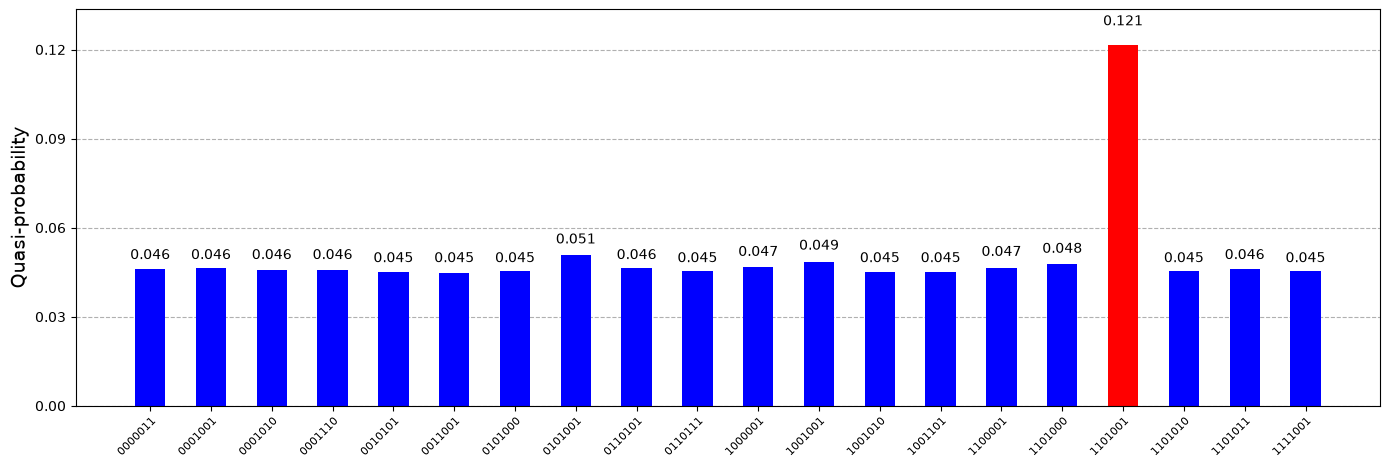

<Figure size 640x480 with 0 Axes>

In [38]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_distribution

# %matplotlib inline

dist = dists[best_iterations - 1]

# Bitstrings that must appear in red
red_states = marked_states

# Get the 20 most frequent outcomes
top_20 = dict(sorted(dist.items(), key=lambda item: item[1], reverse=True)[:20])

# Force all red states into the selection
for state in red_states:
    if state in dist:
        top_20[state] = dist[state]

# Plot the selected outcomes
fig = plot_distribution(top_20, figsize=(14, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in red_states:
        bar.set_facecolor('red')

ax.tick_params(axis='x', labelrotation=45, labelsize=8)
plt.tight_layout()
display(fig)
plt.close(fig)

In [39]:
from pathlib import Path

output_dir = Path("figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Plot the selected outcomes
fig = plot_distribution(dist, figsize=(200, 5), color='blue')

# Color the specified states red
ax = fig.axes[0]
for bar, label in zip(ax.patches, [tick.get_text() for tick in ax.get_xticklabels()]):
    if label in marked_states:
        bar.set_facecolor('red')

fig.savefig(output_dir / "distribution.png", dpi=300, bbox_inches="tight")